In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!pip install transformers SentencePiece py_vncorenlp

In [ ]:
import os
from huggingface_hub import login
import getpass
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    pipeline
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from datasets import load_dataset
import pandas as pd
from datasets import Dataset
from transformers import TrainingArguments
from transformers import Trainer, DataCollatorWithPadding
import numpy as np
from sklearn.metrics import classification_report


In [ ]:
# Lấy token từ mục Secrets của Colab
hf_token =getpass.getpass('HF_TOKEN')

# Tiến hành đăng nhập
login(token=hf_token)

HF_TOKEN··········


### Tải dataset về

In [ ]:
ds = load_dataset("uitnlp/vihsd")

In [ ]:
train_data= pd.DataFrame(data= ds['train'])
val_data= pd.DataFrame(data= ds['validation'])
test_data= pd.DataFrame(data= ds['test'])

In [ ]:
train_data, val_data, test_data

(                                               free_text  label_id
 0      Em được làm fan cứng luôn rồi nè ❤️ reaction q...         0
 1      Đúng là bọn mắt híp lò xo thụt :))) bên việt n...         2
 2               Đậu Văn Cường giờ giống thằng sida hơn à         0
 3      CÔN ĐỒ CỤC SÚC VÔ NHÂN TÍNH ĐỀ NGHI VN. NHÀ NƯ...         2
 4      Từ lý thuyết đến thực hành là cả 1 câu chuyện ...         0
 ...                                                  ...       ...
 24043                  Thả tim cho sự cống hiến của ngài         0
 24044                                             Thua !         0
 24045  Ở Việt Nam thì có khánh sky..hải ngoại có trần...         0
 24046    1:22 ai lớp du chu cờ moo, Duyên dáng quá cô ơi         0
 24047  Cụ này mắt mới cắt mý sao ta kkk đấy vnch đấy ...         0
 
 [24048 rows x 2 columns],
                                               free_text  label_id
 0                                          Coi cười xỉu         0
 1                   

In [ ]:
print(set(train_data['label_id']))

{0, 1, 2}


## Phân loại với model base VisoBert


In [ ]:
# chuyển DataFrame sang định dạng Hugging Face Dataset
train_dataset= Dataset.from_pandas(train_data)
val_dataset= Dataset.from_pandas(val_data)
test_dataset= Dataset.from_pandas(test_data)


In [ ]:
def tokenize(batch):
    return tokenizer(
        batch["free_text"],
        truncation=True,
        max_length=256 #them cai nay de dam bao khong bi tran token khi train
    )
#truncation cắt bớt văn bản nếu dài hơn model


In [ ]:
train_dataset = train_dataset.filter(
    lambda x: isinstance(x["free_text"], str) #chạy thêm filter để chỉ lấy những dòng là chuỗi
)

val_dataset = val_dataset.filter(
    lambda x: isinstance(x["free_text"], str)
)
train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset = val_dataset.map(tokenize, batched=True)
# Vì Hugging Face Trainer sử dụng cột labels để tính loss khi huấn luyện nên cần đổi tên cột
train_dataset= train_dataset.rename_column('label_id', 'labels')
val_dataset= val_dataset.rename_column('label_id', 'labels')

Map:   0%|          | 0/24046 [00:00<?, ? examples/s]

Map:   0%|          | 0/2672 [00:00<?, ? examples/s]

In [ ]:
print(train_dataset[100])

#input_ids: Các token đã chuyển thành số.
#attention_mask: Xác định token nào là nội dung thật.

{'free_text': 'Nghe nói trước đây 1 số thành phần người hà nội kì thị dân vĩnh phúc đúng không nhỉ. Bh sao thì mấy ngừoi đó bị lây hết chưa ấy nhể', 'labels': 0, 'input_ids': [0, 26811, 1198, 99, 13992, 26170, 230, 18, 44068, 2151, 46877, 452, 3, 9069, 287, 17, 7115, 5, 924, 1664, 423, 54, 849, 1701, 14583, 13373, 37, 45, 8594, 351, 102, 241, 2008, 14590, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:

model_name = "uitnlp/visobert"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

In [ ]:

training_args = TrainingArguments(
    output_dir="./ctu_visobert",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none"
)

In [ ]:
# Trainer là công cụ của Hugging Face giúp huấn luyện model mà không cần tự viết vòng lặp PyTorch
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    processing_class=tokenizer
)

In [ ]:
trainer.train()

In [ ]:
trainer.evaluate()

## Phân loại với model PhoBERT
### model này cần có bước tách từ
### EX: học sinh -> học_sinh

In [ ]:
import os
import py_vncorenlp

os.makedirs("/content/vncorenlp", exist_ok=True)

py_vncorenlp.download_model(
    save_dir="/content/vncorenlp"
)

segmenter = py_vncorenlp.VnCoreNLP(
    annotators=["wseg"],
    save_dir="/content/vncorenlp"
)

In [ ]:
def word_segment(text):
    sentences = segmenter.word_segment(text)
    return " ".join(sentences)

def tokenize_word_seg(batch):
    segmented_texts = [
        word_segment(text)
        for text in batch["free_text"]
    ]

    return tokenizer(
        segmented_texts,
        truncation=True,
        max_length=256
    )

In [ ]:
text = "Em được làm fan cứng luôn rồi nè ❤️ reaction quá hay quá cute coi mấy giờ này quá hợp lí =]]]"

print("Original:", text)
print("Segmented:", word_segment(text))

Original: Em được làm fan cứng luôn rồi nè ❤️ reaction quá hay quá cute coi mấy giờ này quá hợp lí =]]]
Segmented: Em được làm fan cứng luôn rồi nè ❤️ reaction quá hay quá cute coi mấy giờ này quá hợp_lí = ] ] ]


In [ ]:

model_name = "vinai/phobert-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
train_dataset = Dataset.from_pandas(train_data)
val_dataset = Dataset.from_pandas(val_data)
test_dataset = Dataset.from_pandas(test_data)

def valid_text(x):
    return isinstance(x["free_text"], str)

train_dataset = train_dataset.filter(valid_text)
val_dataset = val_dataset.filter(valid_text)
test_dataset = test_dataset.filter(valid_text)

train_dataset = train_dataset.map(
    tokenize_word_seg,
    batched=True,
    load_from_cache_file=False
)

val_dataset = val_dataset.map(
    tokenize_word_seg,
    batched=True,
    load_from_cache_file=False
)

test_dataset = test_dataset.map(
    tokenize_word_seg,
    batched=True,
    load_from_cache_file=False
)

train_dataset = train_dataset.rename_column("label_id", "labels")
val_dataset = val_dataset.rename_column("label_id", "labels")
test_dataset = test_dataset.rename_column("label_id", "labels")

Filter:   0%|          | 0/24048 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2672 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6680 [00:00<?, ? examples/s]

Map:   0%|          | 0/24046 [00:00<?, ? examples/s]

Map:   0%|          | 0/2672 [00:00<?, ? examples/s]

Map:   0%|          | 0/6680 [00:00<?, ? examples/s]

In [ ]:
train_dataset[0]

{'free_text': 'Em được làm fan cứng luôn rồi nè ❤️ reaction quá hay quá cute coi mấy giờ này quá hợp lí =]]]',
 'labels': 0,
 'input_ids': [0,
  1350,
  11,
  47,
  1818,
  2951,
  236,
  182,
  21091,
  3,
  3,
  2938,
  43230,
  204,
  118,
  204,
  5109,
  3915,
  774,
  849,
  232,
  23,
  204,
  21905,
  4836,
  2705,
  2705,
  2705,
  2],
 'attention_mask': [1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1]}

In [ ]:
print(train_data["label_id"].value_counts())

label_id
0    19886
2     2556
1     1606
Name: count, dtype: int64


In [ ]:
training_args = TrainingArguments(
    output_dir="./ctu_phobert_finetuned",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    report_to="none"
)

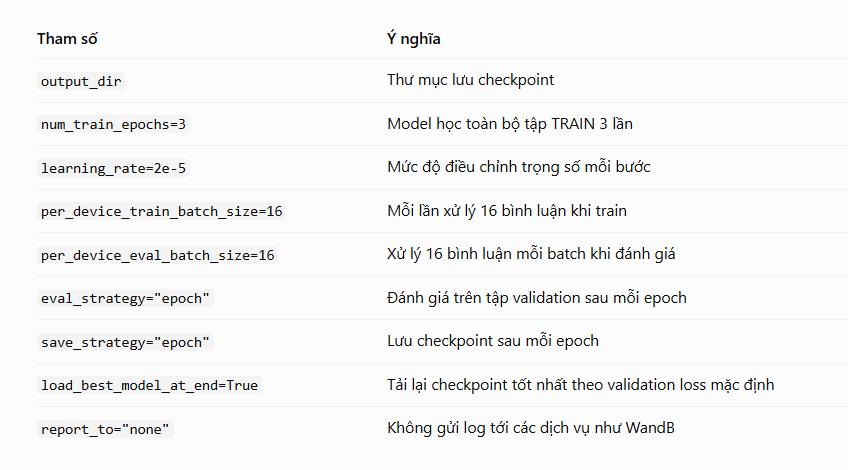

In [ ]:
# Trainer là công cụ của Hugging Face giúp huấn luyện model mà không cần tự viết vòng lặp PyTorch
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    processing_class=tokenizer
)

In [ ]:
print("Token dài nhất:", max(len(x) for x in train_dataset["input_ids"]))
print("Các nhãn:", set(train_dataset["labels"]))
print("Số nhãn model:", model.config.num_labels)

Token dài nhất: 256
Các nhãn: {0, 1, 2}
Số nhãn model: 2


In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.373310,0.374575
2,0.296289,0.389069
3,0.225926,0.394638


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4509, training_loss=0.32644727082547553, metrics={'train_runtime': 757.324, 'train_samples_per_second': 95.254, 'train_steps_per_second': 5.954, 'total_flos': 1760099263465032.0, 'train_loss': 0.32644727082547553, 'epoch': 3.0})

In [ ]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch
0.225926,0.374575,3


{'eval_loss': 0.37457484006881714}

## Model Qwen 2.5 3B

In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

model_name = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()



config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 2048)
    (layers): ModuleList(
      (0-35): 36 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=True)
          (k_proj): Linear(in_features=2048, out_features=256, bias=True)
          (v_proj): Linear(in_features=2048, out_features=256, bias=True)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=2048, out_features=11008, bias=False)
          (up_proj): Linear(in_features=2048, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((2048,), eps=1e-06)
    (ro

In [ ]:

SYSTEM_PROMPT = """
You are a Vietnamese toxic comment classification system.

Your task is to classify Vietnamese comments into exactly one of
three categories:

0 - CLEAN:
Normal, neutral, or polite comments. No offensive or hateful content.
Constructive criticism and negative opinions without personal insults
belong to this category.

1 - OFFENSIVE:
Comments containing insults, profanity, personal attacks,
or abusive language that do not meet the HATE criteria.

2 - HATE:
Comments that attack, dehumanize, express hatred toward,
or encourage discrimination or violence against people
based on protected characteristics such as ethnicity,
religion, nationality, gender, or sexual orientation.

Classification rules:
- Consider the meaning and context of the Vietnamese comment.
- Distinguish criticism from personal insults.
- If both OFFENSIVE and HATE apply, choose HATE.
- Do not classify quoted hateful language as HATE automatically;
  consider whether the speaker endorses it.
- Return exactly one digit: 0, 1, or 2.
- Do not explain your answer.
- Do not include labels, punctuation, or additional text.
"""

def classify_comment(comment):
    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": f"Classify this Vietnamese comment:\n{comment}"
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        [text],
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=4,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_ids = outputs[
        0, inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response if response in {"0", "1", "2"} else None


In [ ]:
y_pred=[]
for comment in val_dataset["free_text"]:
    print(comment)
    y_pred.append(classify_comment(comment))

Coi cười xỉu
Chi ba vang ngoc dep va tre mai
Chần vần một đống, không ai đoán trước được đừng xưng hô tiên tri
Du học sinh Úc mà lại
Dm báo lá cải.. Nghĩ gì khi ở qn mà có hơn 30% hộ nghèo.. Lên google hỏi xem tỉnh nào kinh tế lớn nhất cả nước
Mai Đoàn mới nãy không thấy ai rep cmt vừa rep xong thấy quá tr người luôn 😅 4G như quẹt vậy á
My su
Muốn có 1 cô em trong bộ tộc cùng hợp tác để ra sản phẩm cạnh tranh cùng Tùng 🙂
gays lên nn
@Ngoc Quynh Nhu Nguyen Nó góp ý thì có ngon vào thẳng Facebook Linda mà góp, đm góp trên đây cho cha mẹ nó đọc hả gì. Thứ ngu mà đéo biết nhận xét
Link đâu thằng kia
😮 Nghe lại vẫn ghiền.
From Mixi Long An chúc a và gia đình lễ Vui Vẻ
Chủ tịch công ty này đc
Có vẻ rất thuyết phục nha mn =))
Nguyễn Vy Út Tuyền Việt Nam! 3 mấy ca trường học dc nghỉ, nhật 1 vùng đã 80 ca thì lại k thấy động tĩnh... bất hạnh =))
Tới quảng cáo coi cũng hay nữa quý dzị😌😌
Loạn, loạn hết mẹ nó rồi. Con thắm bây giờ chuyển sang trình bày văn hoa lịch thiệp, thằng ngã cây thì đi làm 

## Đánh giá model

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

valid_mask = np.array([p in (0, 1, 2, "0", "1", "2") for p in y_pred])

y_true_valid = y_true[valid_mask]
y_pred_valid = np.array([
    int(p) for p, valid in zip(y_pred, valid_mask) if valid
])

print(f"Valid rate: {valid_mask.mean():.2%}")

if len(y_pred_valid) > 0:
    print(classification_report(
        y_true_valid,
        y_pred_valid,
        labels=[0, 1, 2],
        target_names=["CLEAN", "OFFENSIVE", "HATE"],
        zero_division=0
    ))

Valid rate: 100.00%
              precision    recall  f1-score   support

       CLEAN       0.94      0.55      0.70      2190
   OFFENSIVE       0.11      0.05      0.07       212
        HATE       0.18      0.87      0.30       270

    accuracy                           0.55      2672
   macro avg       0.41      0.49      0.35      2672
weighted avg       0.80      0.55      0.61      2672



In [ ]:
y_pred

['2',
 '0',
 '0',
 '2',
 '2',
 '0',
 '2',
 '2',
 '2',
 '2',
 '1',
 '0',
 '0',
 '2',
 '0',
 '2',
 '0',
 '2',
 '0',
 '2',
 '2',
 '2',
 '0',
 '2',
 '2',
 '2',
 '2',
 '2',
 '2',
 '0',
 '2',
 '2',
 '2',
 '2',
 '2',
 '2',
 '0',
 '2',
 '2',
 '0',
 '2',
 '2',
 '0',
 '2',
 '1',
 '0',
 '0',
 '0',
 '2',
 '0',
 '0',
 '2',
 '2',
 '2',
 '0',
 '0',
 '0',
 '1',
 '0',
 '2',
 '0',
 '0',
 '0',
 '2',
 '2',
 '2',
 '2',
 '0',
 '0',
 '0',
 '2',
 '0',
 '0',
 '2',
 '0',
 '2',
 '0',
 '0',
 '0',
 '0',
 '0',
 '2',
 '2',
 '0',
 '0',
 '0',
 '0',
 '0',
 '0',
 '0',
 '0',
 '2',
 '0',
 '0',
 '2',
 '2',
 '0',
 '2',
 '0',
 '0',
 '2',
 '0',
 '1',
 '0',
 '0',
 '0',
 '2',
 '0',
 '0',
 '2',
 '0',
 '0',
 '0',
 '2',
 '2',
 '0',
 '2',
 '0',
 '0',
 '0',
 '2',
 '0',
 '0',
 '2',
 '2',
 '0',
 '2',
 '0',
 '0',
 '0',
 '2',
 '0',
 '2',
 '0',
 '0',
 '0',
 '0',
 '1',
 '2',
 '0',
 '2',
 '2',
 '2',
 '0',
 '0',
 '2',
 '2',
 '0',
 '2',
 '0',
 '2',
 '0',
 '2',
 '2',
 '0',
 '0',
 '0',
 '2',
 '1',
 '2',
 '2',
 '2',
 '0',
 '2',
 '2',
 '2',
 '2'

In [ ]:

pred = trainer.predict(val_dataset)

y_pred = np.argmax(pred.predictions, axis=1)
y_true = pred.label_ids

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=["CLEAN", "OFFENSIVE", "HATE"],
    zero_division=0
))

              precision    recall  f1-score   support

       CLEAN       0.92      0.96      0.94      2190
   OFFENSIVE       0.55      0.20      0.29       212
        HATE       0.57      0.63      0.60       270

    accuracy                           0.87      2672
   macro avg       0.68      0.60      0.61      2672
weighted avg       0.85      0.87      0.85      2672



## Lưu model lại

In [ ]:
trainer.save_model("drive/MyDrive/train_model_text_classification/ctu_phobert")
tokenizer.save_pretrained("drive/MyDrive/train_model_text_classification/ctu_phobert")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('drive/MyDrive/train_model_text_classification/ctu_phobert/tokenizer_config.json',
 'drive/MyDrive/train_model_text_classification/ctu_phobert/chat_template.jinja',
 'drive/MyDrive/train_model_text_classification/ctu_phobert/tokenizer.json')

In [ ]:
#Sử dụng mô hình đã tinh chỉnh

from transformers import pipeline
model_path= ""
classifier = pipeline(
    "text-classification",
    model=model_path,
    tokenizer=model_path,
    device=0
)

classifier("Đồ Bắc Kỳ")

In [ ]:
#dự đoán nhiều cái cùng lúc

comments = [
    "Hôm nay vui quá!",
    "Mày nói chuyện ngu thật!",
    "Bài viết này rất hữu ích"
]

results = classifier(comments)

for comment, result in zip(comments, results):
    print(comment, "→", result)